# SQ2 — Spatial patterns of fire-season PM2.5 in BC (PCA + k-means)

**Research sub-question:** *What are the dominant spatial patterns of fire-season PM2.5 across BC's monitoring stations, and how do they relate to when and where fires burn?*

**Pipeline**
1. Clean and preprocess daily PM2.5 (station/period selection, gap filling, log transform, standardization)
2. **PCA** (unsupervised): dominant spatial modes, with North's rule-of-thumb uncertainty
3. **k-means** on the leading PC scores (unsupervised): recurring smoke regimes; choice of *k* and stability checks
4. Link the regimes to **when** (month, year) and **where** (location of recently started fires) fires burn

Put this notebook in the folder that holds the course CSVs, or change `DATA_DIR` below.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

DATA_DIR = Path("data")          # <- change to "." if the CSVs sit next to this notebook
FIRE_SEASON = [5, 6, 7, 8, 9]    # May–September (90% of 2010–2024 burned area starts May–Aug)
START, END = "2016-01-01", "2024-12-31"
COVERAGE_MIN = 80                # % of fire-season days a station must have
MAX_GAP = 3                      # interpolate gaps of at most this many days
N_PCS = 4                        # PCs passed to k-means (chosen in Section 3)
K = 5                            # number of clusters (chosen in Section 4)
FIRE_WINDOW = 30                 # a fire counts as "active" for this many days after its start date
SEED = 0

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE = "#2a78d6", "#eb6834"

## 1. Load data

In [2]:
meta = pd.read_csv(DATA_DIR / "station_metadata.csv", dtype={"station_id": str}).set_index("station_id")
pm_all = pd.read_csv(DATA_DIR / "daily_pm25.csv", index_col=0, parse_dates=True)
fires = pd.read_csv(DATA_DIR / "historical_fires.csv", parse_dates=["fire_start_date"])
try:
    boundary = pd.read_csv(DATA_DIR / "bc_boundary_points.csv")
except FileNotFoundError:
    boundary = None
name = meta["city"].to_dict()

print(f"PM2.5 table: {pm_all.shape[0]} days x {pm_all.shape[1]} stations, {pm_all.index.min().date()} to {pm_all.index.max().date()}")
print(f"Fires: {len(fires):,} records, {fires.fire_start_date.min().date()} to {fires.fire_start_date.max().date()}")
print(f"Negative PM2.5 values: {(pm_all < 0).sum().sum()}  |  max daily value: {pm_all.max().max():.0f} µg/m³")

def draw_bc(ax):
    ax.set_xlim(-131.5, -114); ax.set_ylim(48, 60.2); ax.tick_params(labelsize=7)
    if boundary is not None:
        for _, p in boundary.sort_values(["polygon_id", "point_order"]).groupby("polygon_id"):
            ax.plot(p.longitude, p.latitude, color="#9a998f", lw=0.4)
    ax.set_aspect(1 / np.cos(np.radians(54)))

PM2.5 table: 5479 days x 18 stations, 2010-01-01 to 2024-12-31
Fires: 24,747 records, 1917-07-21 to 2026-03-30
Negative PM2.5 values: 0  |  max daily value: 851 µg/m³


## 2. Preprocessing

**Station and period selection.** PCA needs the same stations on every day. Several stations only start between 2015 and 2022, so we use **2016–2024** and keep stations with data on at least `COVERAGE_MIN`% of fire-season days.

In [3]:
pm = pm_all.loc[START:END]
cov = (pm[pm.index.month.isin(FIRE_SEASON)].notna().mean() * 100).sort_values(ascending=False)
display(cov.rename(name).round(1).to_frame("% fire-season days with data, 2016–2024"))
stations = cov[cov >= COVERAGE_MIN].index.tolist()
dropped = [name[s] for s in cov.index if s not in stations]
print(f"Kept {len(stations)} stations: {[name[s] for s in stations]}")
print(f"Dropped (coverage < {COVERAGE_MIN}%): {dropped}")

,"% fire-season days with data, 2016–2024"
Squamish,99.0
Castlegar,98.8
Burns Lake,98.0
Golden,97.6
Colwood,97.2
Vernon,97.1
Hope,96.8
Williams Lake,96.4
Campbell River,92.5
Fort St John,91.3


Kept 11 stations: ['Squamish', 'Castlegar', 'Burns Lake', 'Golden', 'Colwood', 'Vernon', 'Hope', 'Williams Lake', 'Campbell River', 'Fort St John', 'Vanderhoof']
Dropped (coverage < 80%): ['Kitimat', 'Valemount', 'Prince Rupert', 'Smithers', 'Sparwood', 'Quesnel', 'Tumbler Ridge']


**Missing data.** Short gaps (≤ `MAX_GAP` days, interior only) are filled by linear interpolation on the full daily series, *before* restricting to fire season, so no values are borrowed across the winter. Days that still have any missing station are dropped (PCA and k-means need complete rows).

**Transform.** PM2.5 is strongly right-skewed (most days are clean; smoke days reach hundreds of µg/m³). We use `log(1 + PM2.5)` so a few extreme days don't dominate the covariance, then standardize each station (zero mean, unit variance) so PCA is done on the correlation matrix and every station counts equally regardless of its typical level.

Gap-filled fire-season values: 199 (1.3% of station-days)
Fire-season days: 1377  ->  complete days kept: 932 (68%)


date,2016,2017,2018,2019,2020,2021,2022,2023,2024
complete days,123,114,104,51,102,142,89,85,122


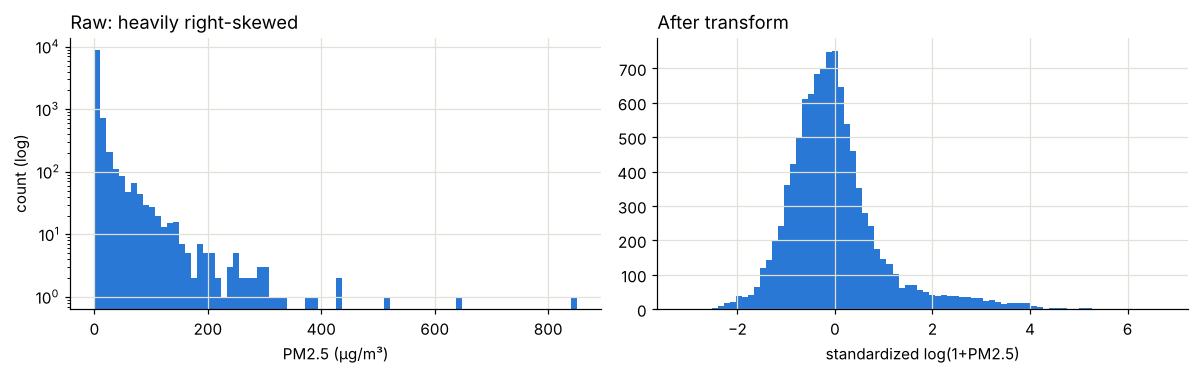

In [4]:
raw = pm[stations]
def fill_short_gaps(col, max_gap=MAX_GAP):
    # Linearly interpolate gaps of <= max_gap days and leave longer gaps completely empty.
    # (pandas' interpolate(limit=...) on its own would fill the first max_gap days of a long gap.)
    missing = col.isna()
    gap_len = missing.groupby((~missing).cumsum()).transform("sum")   # length of the gap each NaN belongs to
    return col.interpolate(limit_area="inside").where(~(missing & (gap_len > max_gap)))

filled = raw.apply(fill_short_gaps)
fsm = raw.index.month.isin(FIRE_SEASON)
n_filled = int(filled[fsm].notna().sum().sum() - raw[fsm].notna().sum().sum())
X = filled[filled.index.month.isin(FIRE_SEASON)]
n_fs = len(X)
X = X.dropna()
print(f"Gap-filled fire-season values: {n_filled} ({n_filled / raw[fsm].size:.1%} of station-days)")
print(f"Fire-season days: {n_fs}  ->  complete days kept: {len(X)} ({len(X)/n_fs:.0%})")
display(X.groupby(X.index.year).size().to_frame("complete days").T)

logX = np.log1p(X)
Z = (logX - logX.mean()) / logX.std()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(X.values.ravel(), bins=80, color=BLUE); ax[0].set_yscale("log")
ax[0].set_xlabel("PM2.5 (µg/m³)"); ax[0].set_ylabel("count (log)"); ax[0].set_title("Raw: heavily right-skewed", loc="left")
ax[1].hist(Z.values.ravel(), bins=80, color=BLUE)
ax[1].set_xlabel("standardized log(1+PM2.5)"); ax[1].set_title("After transform", loc="left")
plt.tight_layout(); plt.show()

## 3. PCA

PCA on the standardized matrix `Z` (days × stations). Each eigenvector (loading pattern) is a spatial mode; the PC score is its daily amplitude.

**North's rule of thumb:** sampling error of eigenvalue λ is about λ·√(2/N\*). Daily PM2.5 is strongly autocorrelated, so we use an effective sample size N\* = N(1−r₁)/(1+r₁), with r₁ the mean lag-1 autocorrelation of the leading PC scores. Modes whose error bars overlap are not well separated and should be interpreted together.

In [5]:
pca = PCA().fit(Z)
scores = pd.DataFrame(pca.transform(Z), index=Z.index, columns=[f"PC{i+1}" for i in range(Z.shape[1])])
loadings = pd.DataFrame(pca.components_.T, index=stations, columns=scores.columns)
# sign convention: make PC1 loadings positive (sign of an eigenvector is arbitrary)
if loadings["PC1"].sum() < 0:
    loadings["PC1"] *= -1; scores["PC1"] *= -1

lam, evr = pca.explained_variance_, pca.explained_variance_ratio_
r1 = np.mean([scores[f"PC{i}"].autocorr() for i in range(1, 5)])
N = len(Z); Neff = N * (1 - r1) / (1 + r1); err = lam * np.sqrt(2 / Neff)
spec = pd.DataFrame({"eigenvalue": lam, "± North": err, "% variance": evr * 100,
                     "cumulative %": evr.cumsum() * 100}, index=scores.columns).round(2)
print(f"N = {N} days, mean lag-1 autocorrelation r1 = {r1:.2f}, effective N* ≈ {Neff:.0f}")
display(spec.head(6))
display(loadings.iloc[:, :4].rename(index=name).round(2))

N = 932 days, mean lag-1 autocorrelation r1 = 0.76, effective N* ≈ 125


,eigenvalue,± North,% variance,cumulative %
PC1,5.95,0.75,54.11,54.11
PC2,1.32,0.17,11.97,66.08
PC3,1.16,0.15,10.54,76.61
PC4,0.64,0.08,5.85,82.46
PC5,0.49,0.06,4.48,86.94
PC6,0.36,0.04,3.23,90.17


,PC1,PC2,PC3,PC4
Squamish,0.34,-0.23,-0.16,-0.24
Castlegar,0.34,-0.10,0.35,-0.06
Burns Lake,0.25,0.38,-0.41,0.04
Golden,0.33,0.04,0.46,-0.05
Colwood,0.26,-0.31,-0.45,-0.29
Vernon,0.35,-0.06,0.33,-0.09
Hope,0.33,-0.21,-0.14,-0.33
Williams Lake,0.32,0.12,0.21,0.35
Campbell River,0.21,-0.45,-0.22,0.75
Fort St John,0.23,0.55,-0.15,-0.05


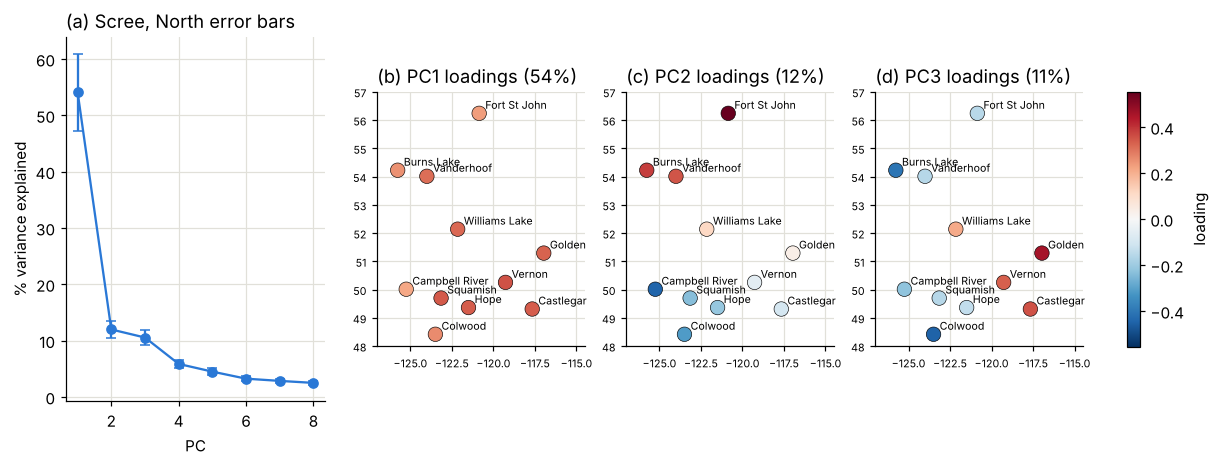

In [6]:
fig = plt.figure(figsize=(14, 4.3))
ax0 = fig.add_subplot(1, 4, 1)
ax0.errorbar(range(1, 9), evr[:8] * 100, yerr=err[:8] / lam.sum() * 100, fmt="o-", color=BLUE, capsize=3)
ax0.set_xlabel("PC"); ax0.set_ylabel("% variance explained"); ax0.set_title("(a) Scree, North error bars", loc="left")
m = meta.loc[stations]
for j, pc in enumerate(["PC1", "PC2", "PC3"]):
    ax = fig.add_subplot(1, 4, j + 2); draw_bc(ax)
    v = loadings[pc]; lim = np.abs(loadings[["PC1", "PC2", "PC3"]].values).max()
    sc = ax.scatter(m.longitude, m.latitude, c=v, cmap="RdBu_r", vmin=-lim, vmax=lim, s=90, edgecolor="k", lw=0.4, zorder=3)
    for s, r in m.iterrows():
        ax.annotate(name[s], (r.longitude, r.latitude), xytext=(4, 3), textcoords="offset points", fontsize=7)
    ax.set_title(f"({'bcd'[j]}) {pc} loadings ({evr[j]*100:.0f}%)", loc="left"); ax.set_xlim(-127, -114.5); ax.set_ylim(48, 57)
fig.colorbar(sc, ax=fig.axes[1:], shrink=0.7, label="loading")
plt.savefig("SQ2_fig1_pca.png", bbox_inches="tight"); plt.show()

**How many PCs to keep for clustering?** We pass the first `N_PCS` = 4 PCs (≈ 83% of variance) to k-means. PCs 5+ each explain < 5% and are mostly single-station noise. Clustering on PC scores rather than raw data removes that noise and keeps each mode's real weight (scores are not re-standardized).

### PC1 amplitude vs. province-wide fire activity

Spearman rho, PC1 score vs BC area burned by fires started in previous 30 d: 0.54
Spearman rho, PC2 score vs BC area burned by fires started in previous 30 d: 0.22
Spearman rho, PC3 score vs BC area burned by fires started in previous 30 d: 0.20


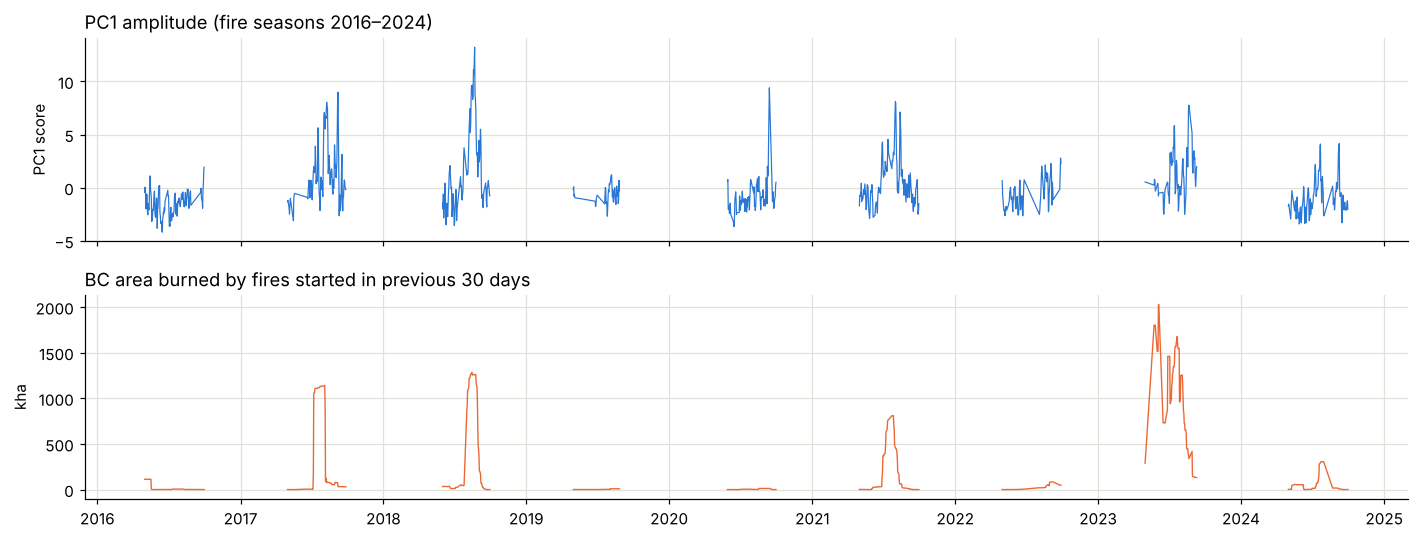

In [7]:
f = fires[(fires.fire_start_date >= pd.Timestamp(START) - pd.Timedelta(days=FIRE_WINDOW)) &
          (fires.fire_start_date <= END)].copy()
days = pd.date_range(pd.Timestamp(START) - pd.Timedelta(days=FIRE_WINDOW), END)
active_area = (f.groupby("fire_start_date")["size"].sum().reindex(days, fill_value=0)
                 .rolling(FIRE_WINDOW, min_periods=1).sum())
a = active_area.reindex(scores.index)
from scipy.stats import spearmanr
for pc in ["PC1", "PC2", "PC3"]:
    print(f"Spearman rho, {pc} score vs BC area burned by fires started in previous {FIRE_WINDOW} d: "
          f"{spearmanr(scores[pc], a)[0]:.2f}")

fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
for yr, g in scores.groupby(scores.index.year):
    ax[0].plot(g.index, g.PC1, color=BLUE, lw=0.8)
    ax[1].plot(g.index, a.loc[g.index] / 1e3, color=ORANGE, lw=0.9)
ax[0].set_ylabel("PC1 score"); ax[0].set_title("PC1 amplitude (fire seasons 2016–2024)", loc="left")
ax[1].set_ylabel("kha"); ax[1].set_title(f"BC area burned by fires started in previous {FIRE_WINDOW} days", loc="left")
plt.tight_layout(); plt.show()

## 4. k-means on PC scores

**Choosing k.** Silhouette, elbow (inertia), and stability:
- *Seed stability:* adjusted Rand index (ARI) between the reference fit and fits from 10 other random seeds
- *Bootstrap stability:* refit on 20 random 80% subsamples, assign all days, compare to reference (ARI)

ARI = 1 means identical partitions. Silhouette usually favours k = 2 here (smoky vs. clean), but that split says nothing about *where* smoke is. So we choose the largest k that is still stable and gives regimes that are physically distinct.

,inertia,silhouette,seed ARI (min),bootstrap ARI (mean),bootstrap ARI (min),smallest cluster (days)
k,,,,,,
2,4942.614,0.536,0.978,0.953,0.863,150
3,3846.470,0.349,0.840,0.874,0.753,59
4,3289.194,0.243,0.928,0.918,0.841,40
5,2844.676,0.254,0.890,0.889,0.752,42
6,2607.122,0.207,0.501,0.725,0.368,42
7,2405.570,0.217,0.592,0.609,0.422,37
8,2204.938,0.221,0.591,0.740,0.540,20


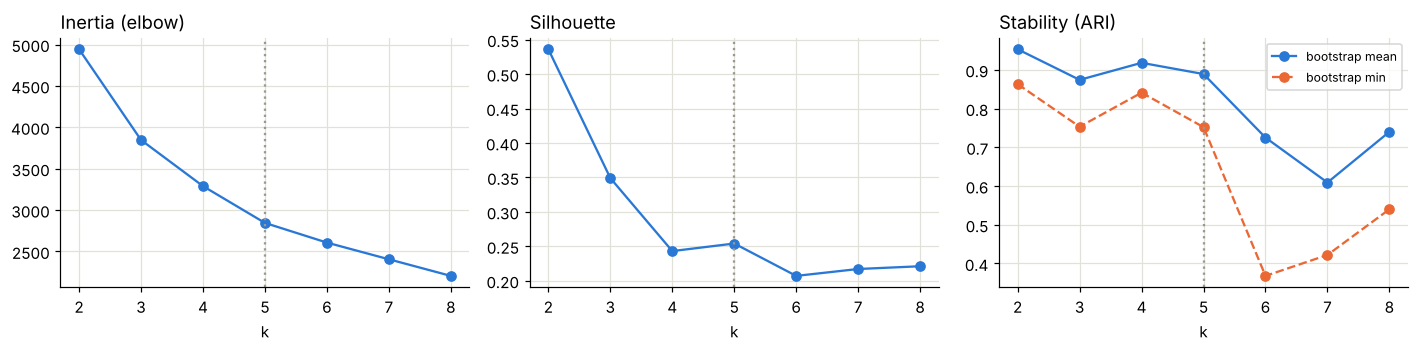

In [8]:
S = scores.iloc[:, :N_PCS].values
rows = []
for k in range(2, 9):
    ref = KMeans(k, n_init=50, random_state=SEED).fit(S)
    seed_ari = [adjusted_rand_score(ref.labels_, KMeans(k, n_init=10, random_state=s).fit(S).labels_) for s in range(1, 11)]
    rng = np.random.default_rng(SEED); boot = []
    for b in range(20):
        idx = rng.choice(len(S), int(0.8 * len(S)), replace=False)
        boot.append(adjusted_rand_score(ref.labels_, KMeans(k, n_init=10, random_state=b).fit(S[idx]).predict(S)))
    rows.append({"k": k, "inertia": ref.inertia_, "silhouette": silhouette_score(S, ref.labels_),
                 "seed ARI (min)": min(seed_ari), "bootstrap ARI (mean)": np.mean(boot),
                 "bootstrap ARI (min)": min(boot), "smallest cluster (days)": np.bincount(ref.labels_).min()})
ksel = pd.DataFrame(rows).set_index("k").round(3); display(ksel)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(ksel.index, ksel.inertia, "o-", color=BLUE); ax[0].set_title("Inertia (elbow)", loc="left")
ax[1].plot(ksel.index, ksel.silhouette, "o-", color=BLUE); ax[1].set_title("Silhouette", loc="left")
ax[2].plot(ksel.index, ksel["bootstrap ARI (mean)"], "o-", color=BLUE, label="bootstrap mean")
ax[2].plot(ksel.index, ksel["bootstrap ARI (min)"], "o--", color=ORANGE, label="bootstrap min")
ax[2].set_title("Stability (ARI)", loc="left"); ax[2].legend(fontsize=8)
for a_ in ax: a_.axvline(K, color="#9a998f", ls=":"); a_.set_xlabel("k")
plt.tight_layout(); plt.show()

In [9]:
km = KMeans(K, n_init=50, random_state=SEED).fit(S)
lab = pd.Series(km.labels_, index=Z.index)
# composite = median raw PM2.5 at each station on the days in each cluster
comp = X.groupby(lab).median().T
order = comp.mean().sort_values().index                       # sort clusters from cleanest to smokiest
remap = {old: new for new, old in enumerate(order, start=1)}
lab = lab.map(remap); comp = comp[order]; comp.columns = range(1, K + 1)

# Names below come from inspecting the composites (next cell). The checks fail loudly
# if a change to the settings above produces different regimes, so names can't silently go stale.
north, se = ["212", "436", "469"], ["11", "433", "419"]        # Vanderhoof/Burns Lake/Fort St John; Vernon/Golden/Castlegar
c = comp
assert c.loc[north].mean().idxmax() in (4, 5) and c.loc[se].mean().idxmax() == 5, "regimes changed — re-check names"
NAMES = {1: "Clean", 2: "Background", 3: "Southern-interior smoke", 4: "Northern smoke", 5: "Severe southern smoke"}
if K == 5:
    assert c.loc[north].mean().idxmax() == 4 and c.loc[se, 3].mean() > c.loc[north, 3].mean(), "regimes changed — re-check names"
else:
    NAMES = {i: f"Cluster {i}" for i in range(1, K + 1)}

summary = pd.DataFrame({"days": lab.value_counts().sort_index(),
                        "% of days": (lab.value_counts(normalize=True).sort_index() * 100).round(1),
                        "mean PM2.5 (all stations)": X.groupby(lab).mean().mean(axis=1).round(1)})
summary.index = [f"{i}. {NAMES[i]}" for i in summary.index]
display(summary)
display(comp.rename(index=name).round(0).rename(columns=lambda i: f"{i}. {NAMES[i]}"))
print("Cluster centroids in PC space:")
cent = scores.iloc[:, :N_PCS].groupby(lab).mean().round(2); cent.index = summary.index; display(cent)

,days,% of days,mean PM2.5 (all stations)
1. Clean,385,41.3,3.7
2. Background,361,38.7,6.4
3. Southern-interior smoke,82,8.8,20.8
4. Northern smoke,62,6.7,23.1
5. Severe southern smoke,42,4.5,63.1


,1. Clean,2. Background,3. Southern-interior smoke,4. Northern smoke,5. Severe southern smoke
Squamish,4.0,6.0,7.0,9.0,50.0
Castlegar,4.0,7.0,26.0,13.0,98.0
Burns Lake,3.0,6.0,4.0,21.0,13.0
Golden,3.0,6.0,34.0,13.0,50.0
Colwood,3.0,4.0,3.0,5.0,24.0
Vernon,3.0,6.0,25.0,14.0,71.0
Hope,3.0,6.0,6.0,9.0,64.0
Williams Lake,3.0,5.0,19.0,15.0,57.0
Campbell River,3.0,4.0,5.0,4.0,14.0
Fort St John,4.0,6.0,6.0,31.0,12.0


Cluster centroids in PC space:


,PC1,PC2,PC3,PC4
1. Clean,-1.85,-0.13,-0.07,0.06
2. Background,0.07,0.01,-0.24,-0.14
3. Southern-interior smoke,1.96,-0.18,2.16,0.43
4. Northern smoke,3.34,2.03,-0.64,0.21
5. Severe southern smoke,7.60,-1.56,-0.58,-0.43


## 5. Regime maps and timing ("when")

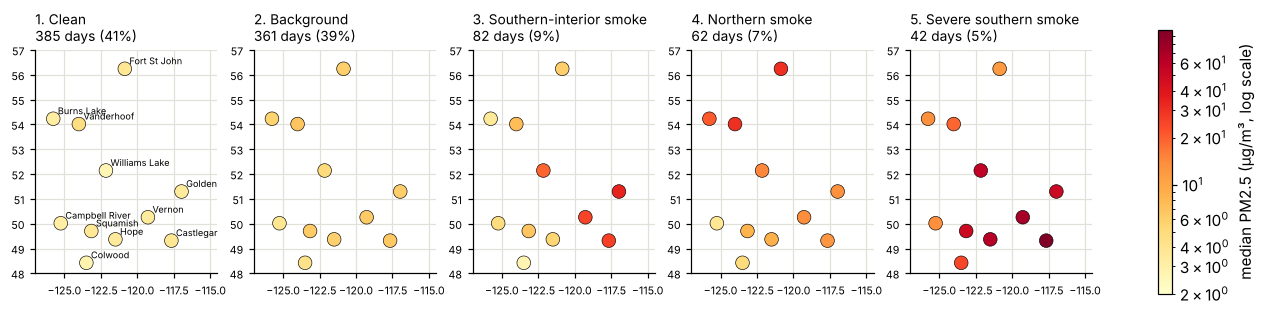

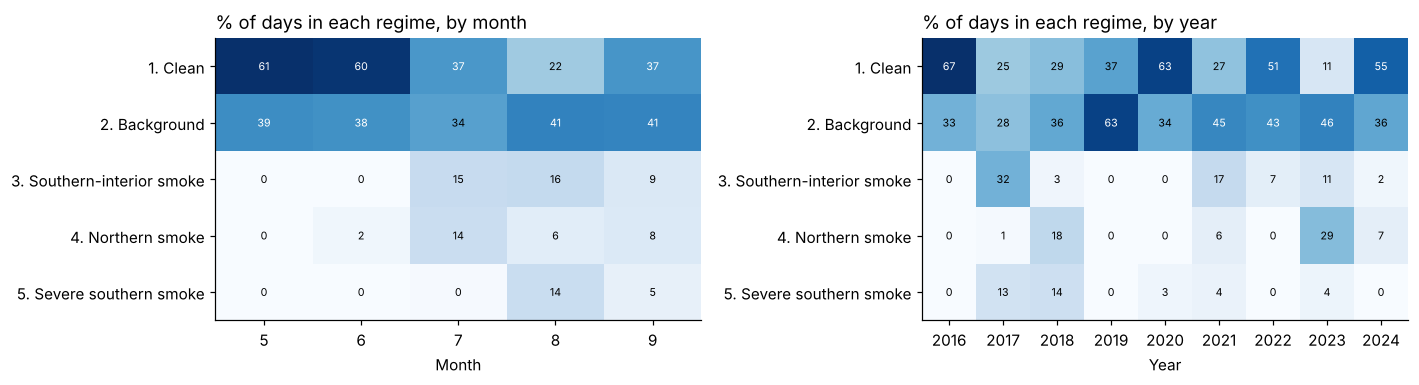

regime,Clean,Background,Southern-interior smoke,Northern smoke,Severe southern smoke
year,,,,,
2016,83,40,0,0,0
2017,29,32,37,1,15
2018,30,37,3,19,15
2019,19,32,0,0,0
2020,64,35,0,0,3
2021,39,64,24,9,6
2022,45,38,6,0,0
2023,9,39,9,25,3
2024,67,44,3,8,0


In [10]:
fig, axes = plt.subplots(1, K, figsize=(3.1 * K, 3.9))
vmax = comp.values.max(); m = meta.loc[stations]
for i, ax in zip(range(1, K + 1), axes):
    draw_bc(ax)
    sc = ax.scatter(m.longitude, m.latitude, c=comp[i].loc[stations], cmap="YlOrRd", s=80,
                    norm=plt.matplotlib.colors.LogNorm(vmin=2, vmax=vmax), edgecolor="k", lw=0.4, zorder=3)
    ax.set_title(f"{i}. {NAMES[i]}\n{(lab == i).sum()} days ({(lab == i).mean():.0%})", fontsize=9, loc="left")
    ax.set_xlim(-127, -114.5); ax.set_ylim(48, 57)
    if i == 1:
        for s, r in m.iterrows():
            ax.annotate(name[s], (r.longitude, r.latitude), xytext=(3, 3), textcoords="offset points", fontsize=6)
fig.colorbar(sc, ax=axes, shrink=0.8, label="median PM2.5 (µg/m³, log scale)")
plt.savefig("SQ2_fig2_regimes.png", bbox_inches="tight"); plt.show()

by_month = pd.crosstab(lab.index.month, lab, normalize="index", rownames=["month"], colnames=["regime"]) * 100
by_year = pd.crosstab(lab.index.year, lab, rownames=["year"], colnames=["regime"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a_, M, xl in [(ax[0], by_month, "Month"), (ax[1], by_year.div(by_year.sum(axis=1), axis=0) * 100, "Year")]:
    im = a_.imshow(M.T.values, cmap="Blues", aspect="auto", vmin=0)
    a_.set_xticks(range(len(M.index)), M.index); a_.set_yticks(range(K), [f"{i}. {NAMES[i]}" for i in M.columns])
    a_.set_xlabel(xl); a_.grid(False)
    for r in range(M.shape[1]):
        for q in range(M.shape[0]):
            a_.text(q, r, f"{M.values[q, r]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if M.values[q, r] > M.values.max() * 0.6 else "k")
ax[0].set_title("% of days in each regime, by month", loc="left"); ax[1].set_title("% of days in each regime, by year", loc="left")
plt.tight_layout(); plt.show()
display(by_year.rename(columns=lambda i: NAMES[i]))

## 6. Linking regimes to where fires burn

For each day we take the fires that **started in the previous `FIRE_WINDOW` days** (the dataset has start dates only, no end dates, so this is a proxy for "burning"). For each regime we average the active burned area per day on a 1°×1° grid, then divide by the same average over **all** fire-season days. A ratio > 1 means fires in that cell are more active than usual when the regime occurs.

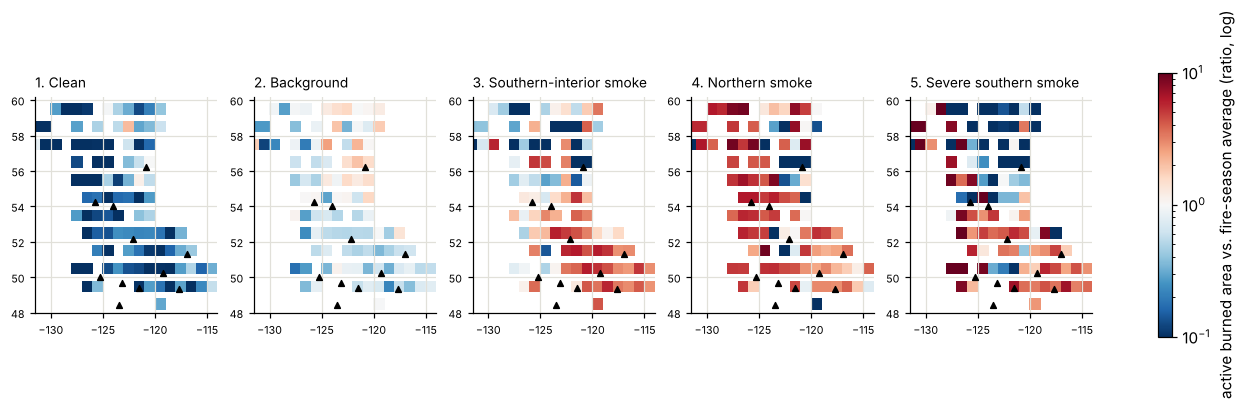

Mean area (kha) of fires started in the previous 30 days, per day in each regime:


region,"Central interior (51–54°N, E of 124°W)",North (≥54°N),"South-east (<51°N, E of 121°W)","South-west (<51°N, W of 121°W)","West-central (51–54°N, W of 124°W)"
1. Clean,10.0,27.0,4.0,1.0,3.0
2. Background,23.0,123.0,13.0,6.0,14.0
3. Southern-interior smoke,240.0,81.0,97.0,24.0,46.0
4. Northern smoke,47.0,393.0,46.0,32.0,154.0
5. Severe southern smoke,149.0,220.0,75.0,9.0,184.0


region,"Central interior (51–54°N, E of 124°W) %",North (≥54°N) %,"South-east (<51°N, E of 121°W) %","South-west (<51°N, W of 121°W) %","West-central (51–54°N, W of 124°W) %"
1. Clean,21.0,60.0,10.0,2.0,7.0
2. Background,13.0,69.0,7.0,3.0,8.0
3. Southern-interior smoke,49.0,17.0,20.0,5.0,9.0
4. Northern smoke,7.0,59.0,7.0,5.0,23.0
5. Severe southern smoke,23.0,35.0,12.0,1.0,29.0


In [11]:
# expand each fire to the days it is treated as active
f_act = f.loc[f.index.repeat(FIRE_WINDOW)].copy()
f_act["day"] = f_act.fire_start_date + pd.to_timedelta(np.tile(np.arange(FIRE_WINDOW), len(f)), unit="D")
f_act = f_act[f_act.day.isin(lab.index)]
f_act["regime"] = f_act.day.map(lab)
f_act["cell_lat"] = np.floor(f_act.lat) + 0.5; f_act["cell_lon"] = np.floor(f_act.lon) + 0.5

ndays = lab.value_counts()
grid_all = f_act.groupby(["cell_lat", "cell_lon"])["size"].sum() / len(lab)
fig, axes = plt.subplots(1, K, figsize=(3.1 * K, 3.9))
for i, ax in zip(range(1, K + 1), axes):
    g = f_act[f_act.regime == i].groupby(["cell_lat", "cell_lon"])["size"].sum() / ndays[i]
    ratio = (g / grid_all).reindex(grid_all.index).fillna(0)
    big = grid_all > grid_all.quantile(0.25)          # skip cells with almost no fire anywhere
    draw_bc(ax)
    sc = ax.scatter([lo for _, lo in ratio[big].index], [la for la, _ in ratio[big].index], c=ratio[big].clip(0.1, 10),
                    cmap="RdBu_r", norm=plt.matplotlib.colors.LogNorm(vmin=0.1, vmax=10), s=55, marker="s", lw=0)
    ax.scatter(meta.loc[stations].longitude, meta.loc[stations].latitude, s=14, c="k", marker="^", zorder=3)
    ax.set_title(f"{i}. {NAMES[i]}", fontsize=9, loc="left")
fig.colorbar(sc, ax=axes, shrink=0.8, label="active burned area vs. fire-season average (ratio, log)")
plt.savefig("SQ2_fig3_fires_by_regime.png", bbox_inches="tight"); plt.show()

# regional summary: where is active burned area, by regime?
def region(r):
    if r.lat >= 54: return "North (≥54°N)"
    if r.lat >= 51: return "West-central (51–54°N, W of 124°W)" if r.lon < -124 else "Central interior (51–54°N, E of 124°W)"
    return "South-west (<51°N, W of 121°W)" if r.lon < -121 else "South-east (<51°N, E of 121°W)"
f_act["region"] = f_act.apply(region, axis=1)
reg = f_act.groupby(["regime", "region"])["size"].sum().unstack(fill_value=0).div(ndays, axis=0) / 1e3
reg = reg.reindex(range(1, K + 1)).fillna(0)
reg.index = [f"{i}. {NAMES[i]}" for i in reg.index]
print("Mean area (kha) of fires started in the previous 30 days, per day in each regime:")
display(reg.round(0)); display((reg.div(reg.sum(axis=1), axis=0) * 100).round(0).add_suffix(" %"))

### Check: smoke that local fires do not explain

Example: mid-September 2020 had heavy smoke in southern BC from US West Coast fires, while BC itself burned very little. If those days fall in a smoke regime, the regime captures smoke transported from outside BC, which BC fire data cannot explain. That's a limitation to discuss.

In [12]:
chk = pd.DataFrame({"regime": lab.loc["2020-09-08":"2020-09-22"].map(NAMES),
                    "mean PM2.5": X.loc["2020-09-08":"2020-09-22"].mean(axis=1).round(0),
                    "BC active burned area (kha)": (a.loc["2020-09-08":"2020-09-22"] / 1e3).round(1)})
display(chk)

,regime,mean PM2.5,BC active burned area (kha)
date,,,
2020-09-08,Background,12.0,12.3
2020-09-09,Background,8.0,12.3
2020-09-10,Background,8.0,12.3
2020-09-11,Severe southern smoke,23.0,12.3
2020-09-12,Severe southern smoke,63.0,12.3
2020-09-13,Severe southern smoke,107.0,12.3
2020-09-21,Clean,4.0,0.1
2020-09-22,Background,6.0,0.1


## 7. Notes for the write-up

- **Preprocessing to report:** station/period selection and coverage threshold; gap filling (≤3 days, interior only); complete-case days; log(1+x) transform; standardization (correlation-matrix PCA).
- **PCA interpretation:** PC1 has same-sign loadings at all stations, so it is a *province-wide* smoke mode (all stations go up together). PC2/PC3 are *contrasts* between regions. A negative PC score means the opposite contrast, not "less than zero smoke". Check North's error bars before treating PC2 and PC3 as separate modes.
- **k-means:** report the k-selection table (silhouette, elbow, ARI stability) and why k was chosen. Interpret clusters with the composite maps, not the centroids.
- **Limitations:** start-date-only fire records (activity window is a proxy); no wind/transport in this analysis; smoke from outside BC; station network is sparse in the north and west; results cover 2016–2024 only.